In [6]:
%pip install minisom kagglehub

Note: you may need to restart the kernel to use updated packages.


'DOSKEY' is not recognized as an internal or external command,
operable program or batch file.

[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



=== Undersampled 1:1 (grid 10x10, thr=0.5): 15012 records, fraud share 50.00% ===
[[1530  722]
 [ 355 1897]]
              precision    recall  f1-score   support

           0      0.812     0.679     0.740      2252
           1      0.724     0.842     0.779      2252

    accuracy                          0.761      4504
   macro avg      0.768     0.761     0.759      4504
weighted avg      0.768     0.761     0.759      4504


=== 50 000 records (grid 10x10, thr=0.5): 50000 records, fraud share 0.59% ===
[[14912     0]
 [   88     0]]
              precision    recall  f1-score   support

           0      0.994     1.000     0.997     14912
           1      0.000     0.000     0.000        88

    accuracy                          0.994     15000
   macro avg      0.497     0.500     0.499     15000
weighted avg      0.988     0.994     0.991     15000


=== 50 000 records (grid 20x20, thr=0.1): 50000 records, fraud share 0.59% ===
[[14912     0]
 [   88     0]]
              

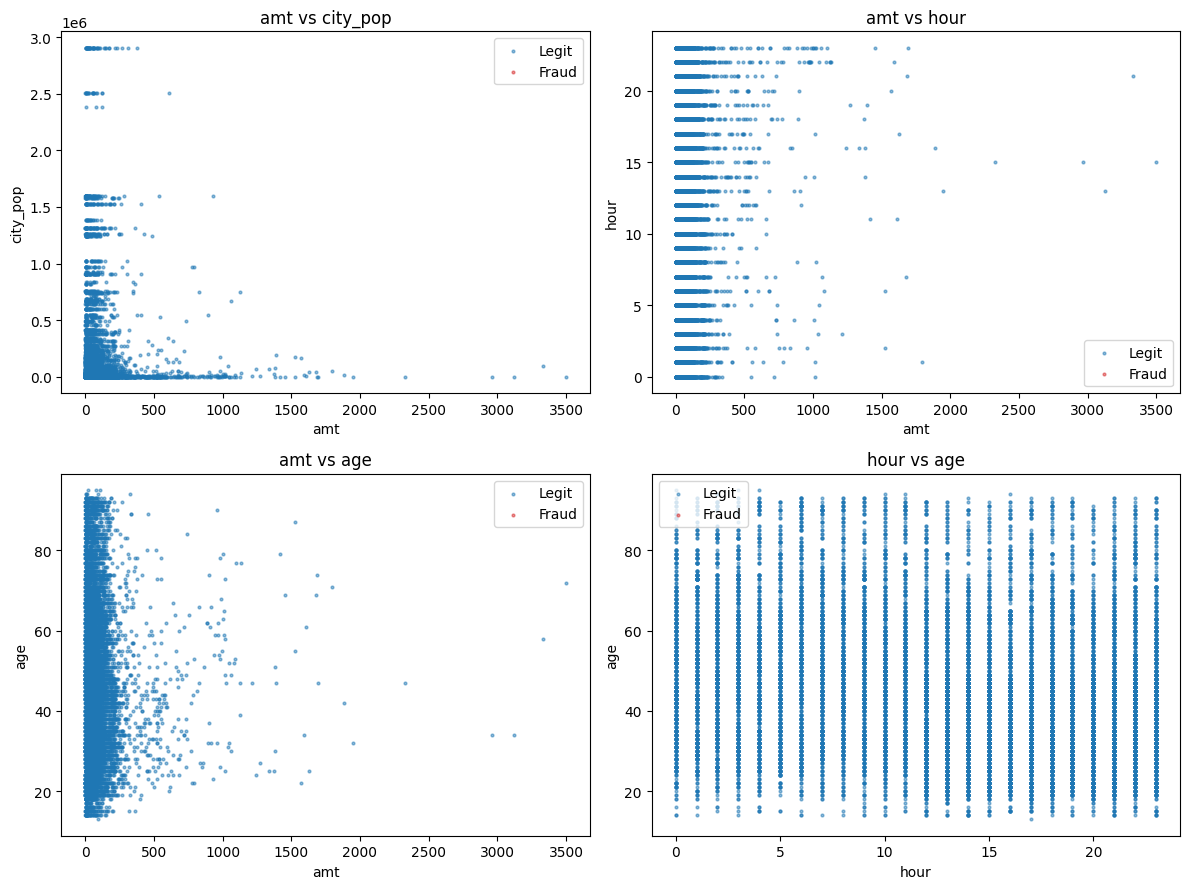

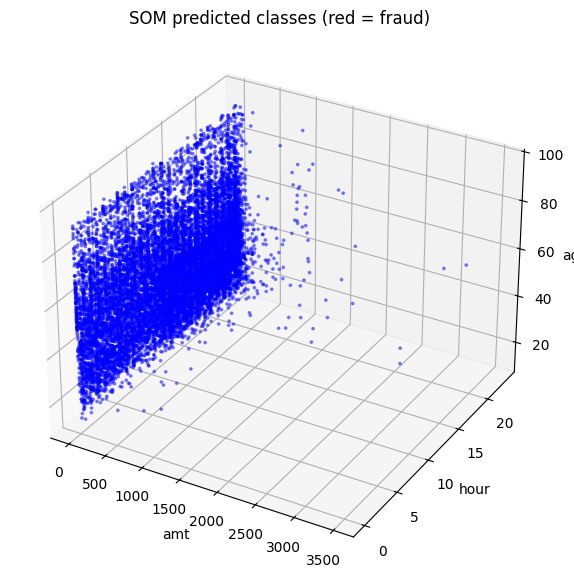

In [7]:
import os, kagglehub
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from minisom import MiniSom
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

path = kagglehub.dataset_download("kartik2112/fraud-detection")
df = pd.read_csv(os.path.join(path, "fraudTrain.csv"))
df["hour"] = pd.to_datetime(df["trans_date_trans_time"]).dt.hour
df["age"] = (pd.to_datetime(df["trans_date_trans_time"]) - pd.to_datetime(df["dob"])).dt.days // 365
cols = ["amt", "city_pop", "hour", "age", "lat", "long"]

def run_som(data, name, thr=0.5, size=10):
    X, y = data[cols].values, data["is_fraud"].values
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
    sc = MinMaxScaler().fit(Xtr)
    Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    som = MiniSom(size, size, len(cols), sigma=1.5, learning_rate=0.5, random_seed=42)
    som.random_weights_init(Xtr); som.train_random(Xtr, 20000)
    # a neuron = "fraud" if its share of fraud training records >= thr (0.5 = majority vote)
    node_cls = {n: int(c[1] / sum(c.values()) >= thr) for n, c in som.labels_map(Xtr, ytr).items()}
    pred = np.array([node_cls.get(som.winner(x), 0) for x in Xte])
    print(f"\n=== {name} (grid {size}x{size}, thr={thr}): {len(data)} records, fraud share {y.mean():.2%} ===")
    print(confusion_matrix(yte, pred))
    print(classification_report(yte, pred, digits=3, zero_division=0))
    return sc.inverse_transform(Xte), pred

# Undersampled 1:1 (as in material) vs 50 000 random records
fraud = df[df.is_fraud == 1]
under = pd.concat([fraud, df[df.is_fraud == 0].sample(len(fraud), random_state=42)])
big = df.sample(50000, random_state=42)
run_som(under, "Undersampled 1:1")
run_som(big, "50 000 records")                               # majority vote
X50, p50 = run_som(big, "50 000 records", thr=0.1, size=20)  # finer grid + lower threshold

# Scatter plots of variable pairs, colored by predicted class
X50 = pd.DataFrame(X50, columns=cols)
pairs = [("amt", "city_pop"), ("amt", "hour"), ("amt", "age"), ("hour", "age")]
fig, ax = plt.subplots(2, 2, figsize=(12, 9))
for a, (x, yv) in zip(ax.ravel(), pairs):
    for c, col, lab in [(0, "tab:blue", "Legit"), (1, "tab:red", "Fraud")]:
        m = p50 == c
        a.scatter(X50.loc[m, x], X50.loc[m, yv], s=4, c=col, alpha=0.5, label=lab)
    a.set(xlabel=x, ylabel=yv, title=f"{x} vs {yv}"); a.legend()
plt.tight_layout(); plt.show()

ax3 = plt.figure(figsize=(8, 7)).add_subplot(projection="3d")
ax3.scatter(X50.amt, X50.hour, X50.age, c=np.where(p50 == 1, "red", "blue"), s=3, alpha=0.4)
ax3.set(xlabel="amt", ylabel="hour", zlabel="age", title="SOM predicted classes (red = fraud)")
plt.show()